# Exploratory Data Analysis (EDA)

Notebook ini mengeksplorasi empat dataset hasil feature engineering untuk mendukung rancangan dashboard Power BI dua halaman: **Macro Overview** dan **Deep-Dive Analysis**.

**Tujuan EDA**
- Menggambarkan ketersediaan sinyal internet seluler di tingkat desa/kelurahan.
- Membandingkan kepemilikan komputer rumah tangga di perkotaan dan perdesaan.
- Mengamati distribusi pengguna internet menurut jenjang pendidikan dan partisipasi sekolah.
- Mengidentifikasi provinsi dengan kondisi infrastruktur digital yang perlu mendapat perhatian.
- Menyiapkan temuan deskriptif yang dapat ditindaklanjuti dalam dashboard.

**Catatan interpretasi**
- Tabel 13 dan 14 adalah distribusi penduduk yang mengakses internet menurut kategori pendidikan/status sekolah. Angkanya bukan tingkat penetrasi internet di dalam masing-masing kelompok.
- Tabel 14 bukan Angka Partisipasi Sekolah (APS).
- Analisis hubungan antarindikator bersifat deskriptif/asosiatif, bukan bukti sebab-akibat.
- Desa dengan sinyal 2.5G atau 3G tetap memiliki sinyal. Kategori tanpa sinyal harus dibedakan dari sinyal generasi lebih rendah.
- Kolom `Perkotaan+Perdesaan` merupakan angka gabungan dari sumber BPS; jangan menghitungnya sebagai rata-rata sederhana dari dua kategori wilayah.

## 1. Persiapan dan pemuatan data

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = Path.cwd()
if not (BASE_DIR / "data").exists():
    # Jika notebook dibuka dari dalam folder notebooks
    BASE_DIR = BASE_DIR.parent

PROCESSED_DIR = BASE_DIR / "data" / "processed"
FINAL_DIR = BASE_DIR / "data" / "final"

files = {
    "sinyal": PROCESSED_DIR / "sinyal_feature.csv",
    "jenjang": PROCESSED_DIR / "akses_jenjang_feature.csv",
    "partisipasi": PROCESSED_DIR / "partisipasi_feature.csv",
    "komputer": PROCESSED_DIR / "komputer_feature.csv",
    "final": FINAL_DIR / "dashboard_pendidikan_final.csv",
}

for name, path in files.items():
    print(f"{name:15} | {'ADA' if path.exists() else 'TIDAK DITEMUKAN'} | {path}")

sinyal = pd.read_csv(files["sinyal"])
jenjang = pd.read_csv(files["jenjang"])
partisipasi = pd.read_csv(files["partisipasi"])
komputer = pd.read_csv(files["komputer"])
df = pd.read_csv(files["final"])

print("\nUkuran dataset final:", df.shape)
display(df.head())

sinyal          | ADA | d:\Dash\data\processed\sinyal_feature.csv
jenjang         | ADA | d:\Dash\data\processed\akses_jenjang_feature.csv
partisipasi     | ADA | d:\Dash\data\processed\partisipasi_feature.csv
komputer        | ADA | d:\Dash\data\processed\komputer_feature.csv
final           | ADA | d:\Dash\data\final\dashboard_pendidikan_final.csv

Ukuran dataset final: (38, 30)


,Provinsi,Desa_3G,Desa_2_5G,Desa_Tanpa_Sinyal,Desa_4G_5G,Jumlah_Kategori_Tersedia,Total_Desa,Desa_Dengan_Sinyal,Persentase_Desa_4G_5G,Total_Kategori,...,Masih Bersekolah,Tidak Sekolah Lagi,Total_Distribusi_Partisipasi,Kategori_Dominan,Persentase_Kategori_Dominan,Perkotaan,Perdesaan,Perkotaan+Perdesaan,Selisih_Kota_Desa,Wilayah_Lebih_Tinggi
0,Aceh,512.0,82.0,74.0,5848.0,4,6516.0,6442.0,89.748312,6516.0,...,27.90,70.44,100.00,Tidak Sekolah Lagi,70.44,26.55,9.47,15.49,17.08,Perkotaan
1,Sumatera Utara,471.0,151.0,207.0,5284.0,4,6113.0,5906.0,86.438737,6113.0,...,28.27,69.62,100.00,Tidak Sekolah Lagi,69.62,20.60,8.43,15.35,12.17,Perkotaan
2,Sumatera Barat,51.0,16.0,25.0,1194.0,4,1286.0,1261.0,92.846034,1286.0,...,30.87,66.51,99.99,Tidak Sekolah Lagi,66.51,28.84,11.83,20.48,17.01,Perkotaan
3,Riau,110.0,44.0,30.0,1686.0,4,1870.0,1840.0,90.160428,1870.0,...,28.26,69.36,100.01,Tidak Sekolah Lagi,69.36,27.82,11.50,17.98,16.32,Perkotaan
4,Jambi,114.0,39.0,27.0,1405.0,4,1585.0,1558.0,88.643533,1585.0,...,27.16,70.29,100.00,Tidak Sekolah Lagi,70.29,30.31,11.41,17.60,18.90,Perkotaan


## 2. Pemeriksaan awal dataset

Memeriksa dimensi, nama kolom, tipe data, duplikasi provinsi, dan missing value. Missing value tidak langsung diisi nol karena beberapa nilai kosong berasal dari tanda strip atau kategori wilayah yang tidak tersedia pada sumber.

In [2]:
print("Dimensi:", df.shape)
print("Jumlah provinsi unik:", df["Provinsi"].nunique())
print("Duplikasi provinsi:", df["Provinsi"].duplicated().sum())

display(pd.DataFrame({
    "Tipe Data": df.dtypes.astype(str),
    "Missing": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
}))

display(df.describe(include="all").T)

Dimensi: (38, 30)
Jumlah provinsi unik: 38
Duplikasi provinsi: 0


,Tipe Data,Missing,Missing (%)
Provinsi,str,0,0.00
Desa_3G,float64,1,2.63
Desa_2_5G,float64,2,5.26
Desa_Tanpa_Sinyal,float64,4,10.53
Desa_4G_5G,float64,0,0.00
Jumlah_Kategori_Tersedia,int64,0,0.00
Total_Desa,float64,4,10.53
Desa_Dengan_Sinyal,float64,2,5.26
Persentase_Desa_4G_5G,float64,4,10.53
Total_Kategori,float64,4,10.53


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Provinsi,38,38,Aceh,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Desa_3G,37.0,NaN,NaN,NaN,132.837838,128.296426,3.0,43.0,87.0,181.0,512.0
Desa_2_5G,36.0,NaN,NaN,NaN,55.777778,60.250482,1.0,19.75,33.5,56.75,247.0
Desa_Tanpa_Sinyal,34.0,NaN,NaN,NaN,121.823529,310.86141,1.0,15.5,39.0,79.25,1667.0
Desa_4G_5G,38.0,NaN,NaN,NaN,1926.605263,2072.424909,192.0,674.0,1161.5,2006.5,8316.0
Jumlah_Kategori_Tersedia,38.0,NaN,NaN,NaN,3.815789,0.608732,1.0,4.0,4.0,4.0,4.0
Total_Desa,34.0,NaN,NaN,NaN,2425.558824,2171.775369,438.0,1083.5,1581.0,2651.25,8563.0
Desa_Dengan_Sinyal,36.0,NaN,NaN,NaN,2207.611111,2179.463581,337.0,881.25,1490.0,2335.25,8562.0
Persentase_Desa_4G_5G,34.0,NaN,NaN,NaN,82.946108,18.529882,15.89404,82.173881,89.009149,92.58334,98.438811
Total_Kategori,34.0,NaN,NaN,NaN,2425.558824,2171.775369,438.0,1083.5,1581.0,2651.25,8563.0


## 3. Pemetaan kelompok pulau

In [3]:
PULAU = {
    "Sumatera": [
        "Aceh", "Sumatera Utara", "Sumatera Barat", "Riau", "Jambi",
        "Sumatera Selatan", "Bengkulu", "Lampung",
        "Kepulauan Bangka Belitung", "Kepulauan Riau"
    ],
    "Jawa": [
        "DKI Jakarta", "Jawa Barat", "Jawa Tengah", "DI Yogyakarta",
        "Jawa Timur", "Banten"
    ],
    "Bali dan Nusa Tenggara": [
        "Bali", "Nusa Tenggara Barat", "Nusa Tenggara Timur"
    ],
    "Kalimantan": [
        "Kalimantan Barat", "Kalimantan Tengah", "Kalimantan Selatan",
        "Kalimantan Timur", "Kalimantan Utara"
    ],
    "Sulawesi": [
        "Sulawesi Utara", "Sulawesi Tengah", "Sulawesi Selatan",
        "Sulawesi Tenggara", "Gorontalo", "Sulawesi Barat"
    ],
    "Maluku": ["Maluku", "Maluku Utara"],
    "Papua": [
        "Papua Barat", "Papua Barat Daya", "Papua",
        "Papua Selatan", "Papua Tengah", "Papua Pegunungan"
    ]
}

province_to_island = {
    province: island
    for island, provinces in PULAU.items()
    for province in provinces
}

df["Wilayah"] = df["Provinsi"].map(province_to_island)

unmapped = df.loc[df["Wilayah"].isna(), "Provinsi"].tolist()
print("Provinsi belum terpetakan:", unmapped)
assert not unmapped, f"Ada provinsi belum terpetakan: {unmapped}"

display(df[["Provinsi", "Wilayah"]].sort_values(["Wilayah", "Provinsi"]))

Provinsi belum terpetakan: []


,Provinsi,Wilayah
16,Bali,Bali dan Nusa Tenggara
17,Nusa Tenggara Barat,Bali dan Nusa Tenggara
18,Nusa Tenggara Timur,Bali dan Nusa Tenggara
15,Banten,Jawa
13,DI Yogyakarta,Jawa
10,DKI Jakarta,Jawa
11,Jawa Barat,Jawa
12,Jawa Tengah,Jawa
14,Jawa Timur,Jawa
19,Kalimantan Barat,Kalimantan


## 4. Infrastruktur sinyal internet seluler — Tabel 7

### 4.1 Komposisi kategori sinyal per provinsi

Kategori 2.5G, 3G, dan 4G/5G menunjukkan adanya penerimaan sinyal dengan teknologi berbeda. `Desa_Tanpa_Sinyal` menunjukkan desa/kelurahan yang tidak menerima sinyal telepon seluler.

Untuk analisis blank spot yang ketat, gunakan:
\[
\%\text{ Desa Tanpa Sinyal} =
\frac{\text{Desa Tanpa Sinyal}}{\text{Total Desa}} \times 100
\]

Jangan menjumlahkan 2.5G dan 3G sebagai blank spot.

In [4]:
signal_complete = df[df["Total_Desa"].notna()].copy()
signal_complete["Persentase_Desa_Tanpa_Sinyal"] = (
    signal_complete["Desa_Tanpa_Sinyal"] /
    signal_complete["Total_Desa"] * 100
)

signal_complete["Persentase_Desa_4G_5G_Hitung"] = (
    signal_complete["Desa_4G_5G"] /
    signal_complete["Total_Desa"] * 100
)

display(
    signal_complete[
        ["Provinsi", "Total_Desa", "Desa_Tanpa_Sinyal",
         "Persentase_Desa_Tanpa_Sinyal", "Persentase_Desa_4G_5G_Hitung"]
    ].sort_values("Persentase_Desa_Tanpa_Sinyal", ascending=False)
)

,Provinsi,Total_Desa,Desa_Tanpa_Sinyal,Persentase_Desa_Tanpa_Sinyal,Persentase_Desa_4G_5G_Hitung
36,Papua Tengah,1208.0,871.0,72.102649,15.894040
37,Papua Pegunungan,2634.0,1667.0,63.287775,17.919514
32,Papua Barat,970.0,163.0,16.804124,73.711340
35,Papua Selatan,690.0,105.0,15.217391,80.000000
34,Papua,1029.0,123.0,11.953353,78.425656
23,Kalimantan Utara,484.0,53.0,10.950413,66.942149
29,Sulawesi Barat,650.0,61.0,9.384615,82.307692
33,Papua Barat Daya,1056.0,81.0,7.670455,87.689394
20,Kalimantan Tengah,1577.0,97.0,6.150919,69.181991
30,Maluku,1262.0,66.0,5.229794,89.461173


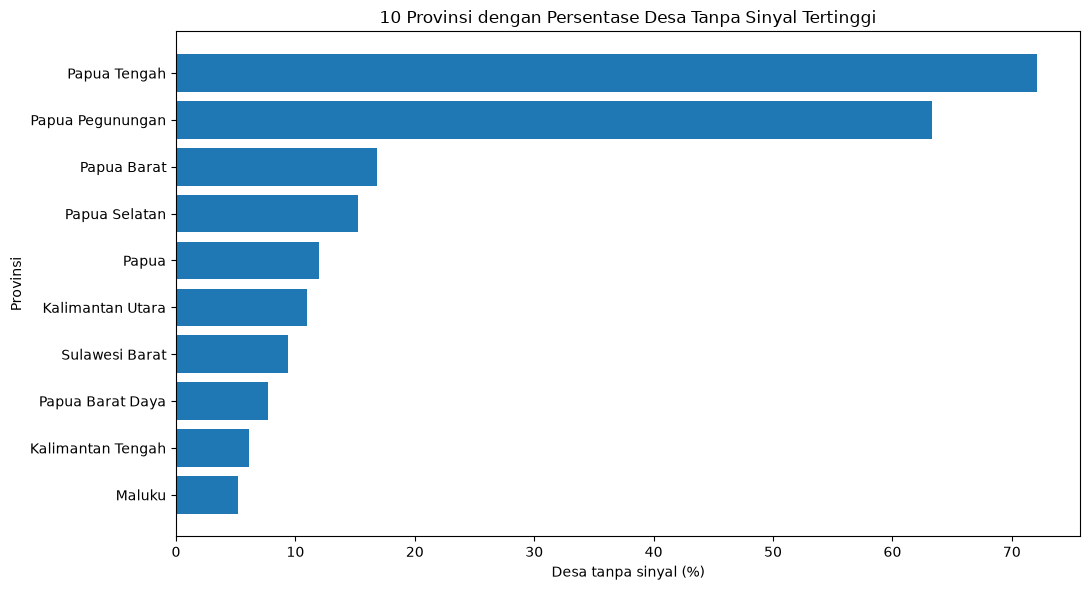

In [5]:
top_no_signal = signal_complete.sort_values(
    "Persentase_Desa_Tanpa_Sinyal", ascending=False
).head(10)

plt.figure(figsize=(11, 6))
plt.barh(
    top_no_signal["Provinsi"][::-1],
    top_no_signal["Persentase_Desa_Tanpa_Sinyal"][::-1]
)
plt.xlabel("Desa tanpa sinyal (%)")
plt.ylabel("Provinsi")
plt.title("10 Provinsi dengan Persentase Desa Tanpa Sinyal Tertinggi")
plt.tight_layout()
plt.show()

### 4.2 Kelengkapan data sinyal

Empat provinsi memiliki satu atau lebih kategori sinyal kosong. Perbandingan persentase hanya dilakukan pada provinsi yang memiliki `Total_Desa` hasil penjumlahan lengkap. Jangan menganggap nilai kosong sebagai nol.

In [6]:
missing_signal = df[
    df[["Desa_3G", "Desa_2_5G", "Desa_Tanpa_Sinyal", "Desa_4G_5G"]]
    .isna().any(axis=1)
]
display(missing_signal[
    ["Provinsi", "Desa_3G", "Desa_2_5G",
     "Desa_Tanpa_Sinyal", "Desa_4G_5G", "Jumlah_Kategori_Tersedia"]
])

,Provinsi,Desa_3G,Desa_2_5G,Desa_Tanpa_Sinyal,Desa_4G_5G,Jumlah_Kategori_Tersedia
8,Kepulauan Bangka Belitung,5.0,NaN,NaN,388.0,2
9,Kepulauan Riau,28.0,12.0,NaN,390.0,3
10,DKI Jakarta,NaN,NaN,NaN,267.0,1
16,Bali,3.0,1.0,NaN,713.0,3


## 5. Kepemilikan komputer rumah tangga — Tabel 25

### 5.1 Perbandingan perkotaan dan perdesaan

`Selisih_Kota_Desa` dinyatakan dalam **poin persentase (pp)**, bukan persen. DKI Jakarta memiliki nilai perdesaan kosong sehingga tidak dapat dibandingkan pada indikator selisih.

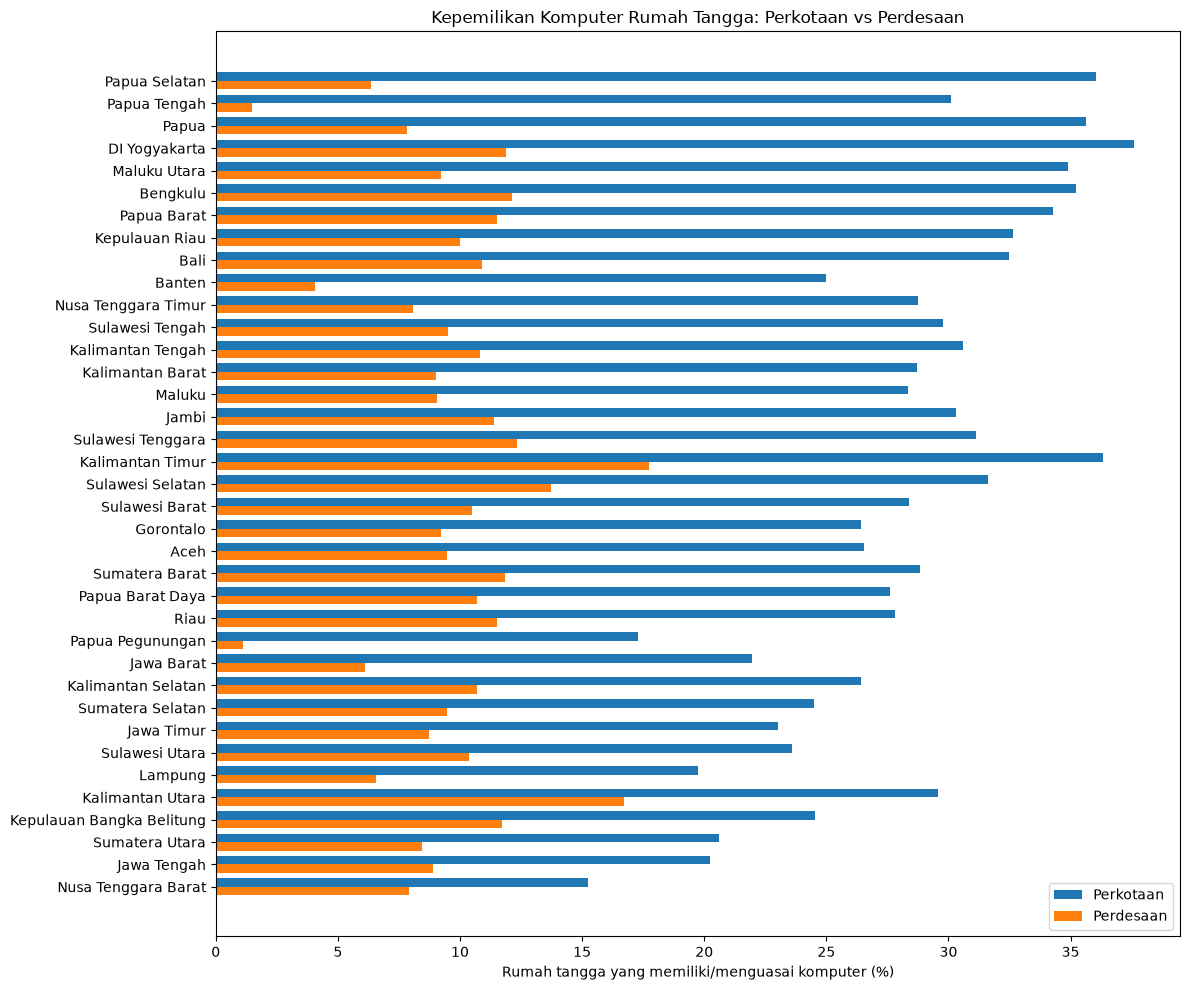

,Provinsi,Perkotaan,Perdesaan,Selisih_Kota_Desa
35,Papua Selatan,36.04,6.34,29.70
36,Papua Tengah,30.12,1.49,28.63
34,Papua,35.64,7.84,27.80
13,DI Yogyakarta,37.60,11.90,25.70
31,Maluku Utara,34.88,9.23,25.65
6,Bengkulu,35.23,12.14,23.09
32,Papua Barat,34.26,11.53,22.73
9,Kepulauan Riau,32.63,10.01,22.62
16,Bali,32.49,10.92,21.57
15,Banten,24.97,4.05,20.92


In [7]:
computer = df.dropna(subset=["Perkotaan", "Perdesaan"]).copy()
computer["Selisih_Kota_Desa"] = computer["Perkotaan"] - computer["Perdesaan"]

computer_sorted = computer.sort_values("Selisih_Kota_Desa", ascending=False)

y = np.arange(len(computer_sorted))
height = 0.38

plt.figure(figsize=(12, 10))
plt.barh(y - height/2, computer_sorted["Perkotaan"], height, label="Perkotaan")
plt.barh(y + height/2, computer_sorted["Perdesaan"], height, label="Perdesaan")
plt.yticks(y, computer_sorted["Provinsi"])
plt.xlabel("Rumah tangga yang memiliki/menguasai komputer (%)")
plt.title("Kepemilikan Komputer Rumah Tangga: Perkotaan vs Perdesaan")
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

display(
    computer_sorted[
        ["Provinsi", "Perkotaan", "Perdesaan", "Selisih_Kota_Desa"]
    ].head(10)
)

### 5.2 Rata-rata provinsi menurut kelompok pulau

Angka berikut adalah **rata-rata sederhana antarprovinsi** dalam kelompok pulau, bukan estimasi persentase nasional berbobot jumlah rumah tangga.

,Perkotaan,Perdesaan,Perkotaan+Perdesaan
Wilayah,,,
Jawa,27.85,7.94,23.65
Kalimantan,30.33,12.99,22.00
Sumatera,27.08,10.25,18.22
Sulawesi,28.48,10.94,17.86
Maluku,31.62,9.14,17.38
Bali dan Nusa Tenggara,25.51,8.97,17.35
Papua,30.16,6.50,14.96


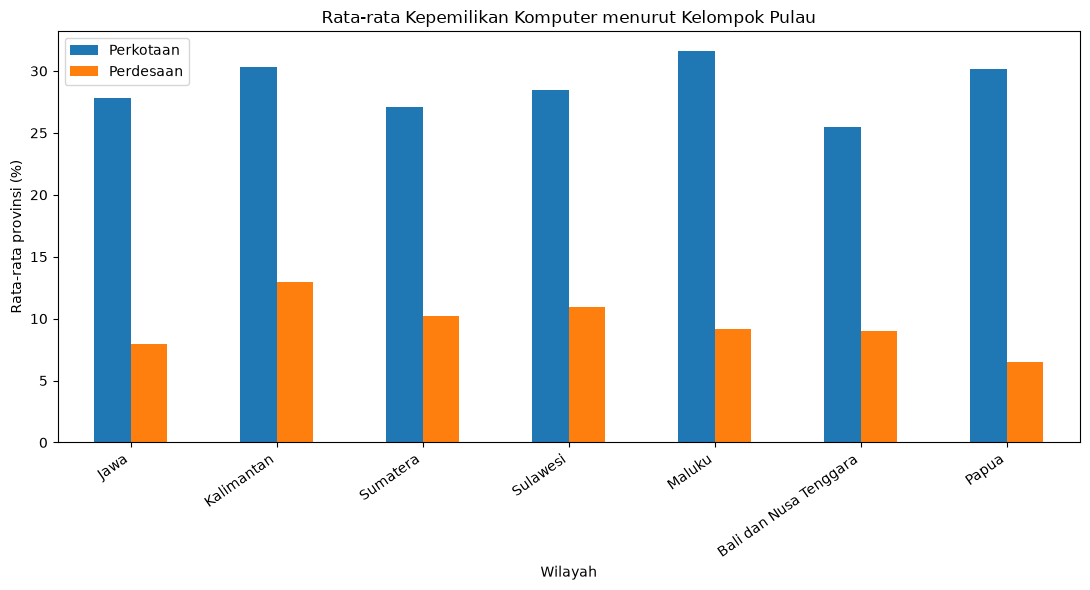

In [8]:
computer_by_island = (
    df.groupby("Wilayah")[["Perkotaan", "Perdesaan", "Perkotaan+Perdesaan"]]
    .mean()
    .sort_values("Perkotaan+Perdesaan", ascending=False)
)

display(computer_by_island.round(2))

computer_by_island[["Perkotaan", "Perdesaan"]].plot(
    kind="bar", figsize=(11, 6)
)
plt.ylabel("Rata-rata provinsi (%)")
plt.title("Rata-rata Kepemilikan Komputer menurut Kelompok Pulau")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 6. Distribusi pengguna internet menurut jenjang pendidikan — Tabel 13

Persentase pada Tabel 13 menggambarkan komposisi penduduk usia 5 tahun ke atas yang mengakses internet menurut jenjang pendidikan yang sedang diduduki. Karena total kategori per provinsi mendekati 100%, interpretasinya adalah komposisi, bukan peluang atau tingkat akses internet dalam setiap jenjang.

,Rata-rata persentase antarprovinsi
SMA,37.32
SD,23.79
SMP,20.42
S1 ke atas,15.76
D1-D3,2.71


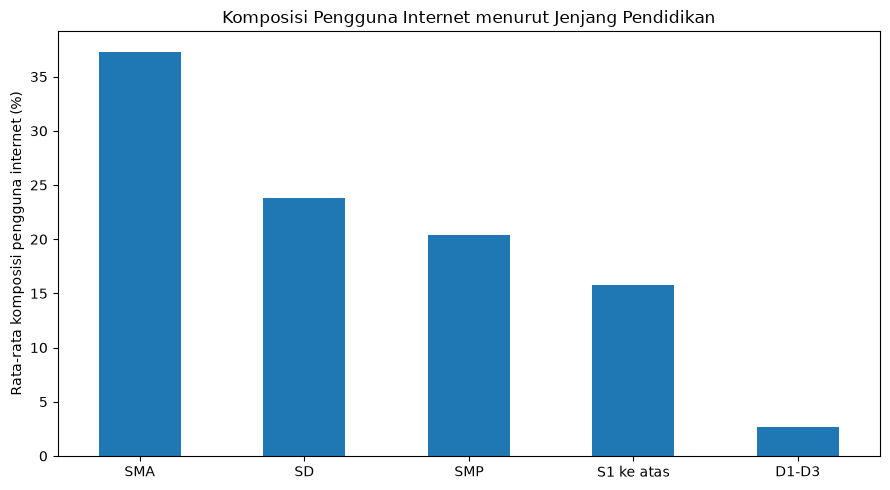

In [9]:
education_cols = ["SD", "SMP", "SMA", "D1-D3", "S1 ke atas"]

education_mean = df[education_cols].mean().sort_values(ascending=False)
display(education_mean.to_frame("Rata-rata persentase antarprovinsi").round(2))

education_mean.plot(kind="bar", figsize=(9, 5))
plt.ylabel("Rata-rata komposisi pengguna internet (%)")
plt.title("Komposisi Pengguna Internet menurut Jenjang Pendidikan")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

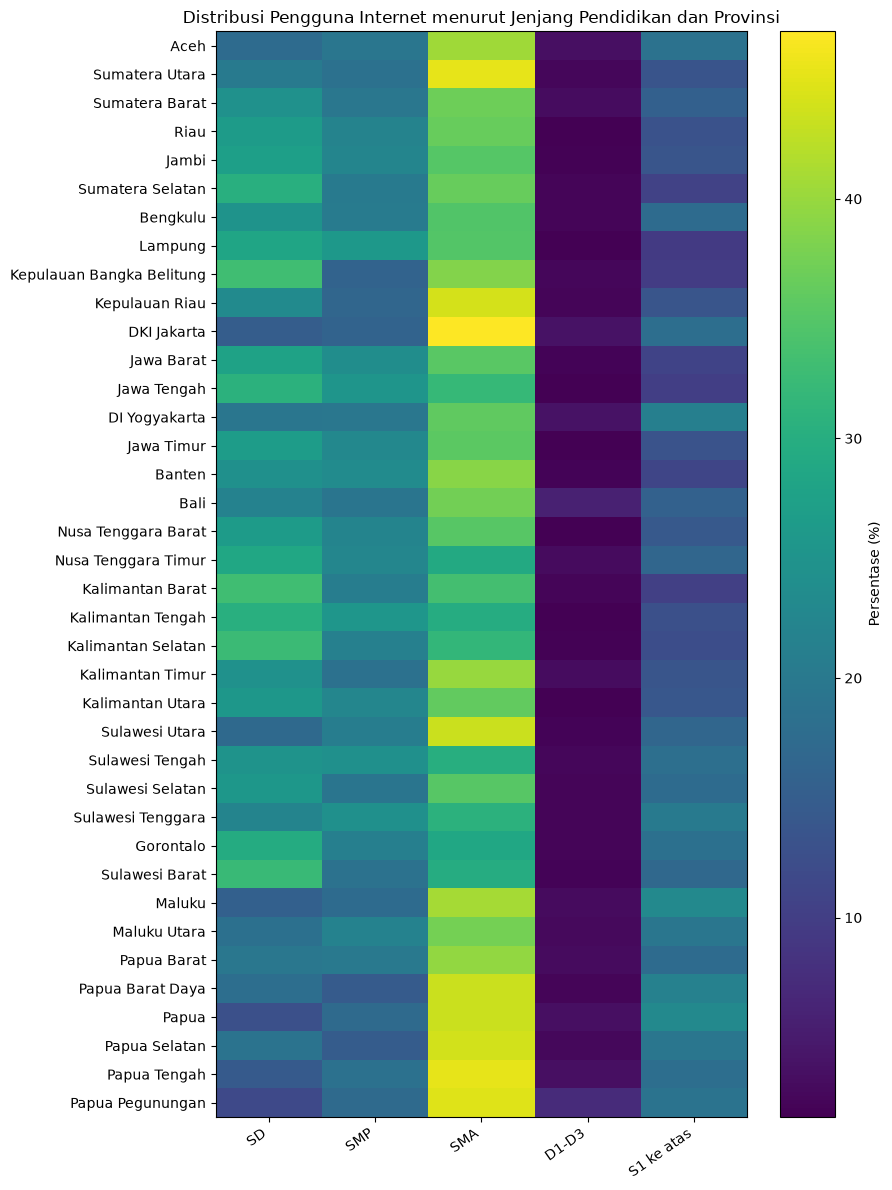

In [10]:
# Heatmap sederhana menggunakan matplotlib
education_matrix = df.set_index("Provinsi")[education_cols]

fig, ax = plt.subplots(figsize=(9, 12))
im = ax.imshow(education_matrix.values, aspect="auto")
ax.set_xticks(range(len(education_cols)))
ax.set_xticklabels(education_cols, rotation=35, ha="right")
ax.set_yticks(range(len(education_matrix.index)))
ax.set_yticklabels(education_matrix.index)
ax.set_title("Distribusi Pengguna Internet menurut Jenjang Pendidikan dan Provinsi")
fig.colorbar(im, ax=ax, label="Persentase (%)")
plt.tight_layout()
plt.show()

### 6.1 Selisih komposisi S1 ke atas dan SD

Indikator ini menunjukkan perbedaan komposisi pengguna internet antara kategori S1 ke atas dan SD. Nilainya tidak menunjukkan kesenjangan penetrasi internet antara mahasiswa dan siswa SD.

In [11]:
df["Selisih_S1_dan_SD_pp"] = df["S1 ke atas"] - df["SD"]

display(
    df[["Provinsi", "SD", "S1 ke atas", "Selisih_S1_dan_SD_pp"]]
    .sort_values("Selisih_S1_dan_SD_pp")
)

,Provinsi,SD,S1 ke atas,Selisih_S1_dan_SD_pp
8,Kepulauan Bangka Belitung,33.04,9.79,-23.25
19,Kalimantan Barat,33.06,10.35,-22.71
12,Jawa Tengah,30.79,10.01,-20.78
21,Kalimantan Selatan,32.55,12.41,-20.14
5,Sumatera Selatan,30.33,10.59,-19.74
7,Lampung,28.25,9.36,-18.89
20,Kalimantan Tengah,30.27,12.67,-17.60
11,Jawa Barat,27.76,10.76,-17.00
29,Sulawesi Barat,32.38,16.95,-15.43
4,Jambi,27.17,13.54,-13.63


## 7. Distribusi pengguna internet menurut partisipasi sekolah — Tabel 14

Tabel 14 menunjukkan komposisi penduduk yang mengakses internet menurut status partisipasi sekolah: tidak/belum pernah sekolah, masih bersekolah, dan tidak sekolah lagi. Ini bukan APS dan bukan persentase pengguna internet di dalam setiap status sekolah.

,Rata-rata persentase antarprovinsi
Tidak Sekolah Lagi,70.61
Masih Bersekolah,26.64
Tidak/Belum Pernah Sekolah,2.75


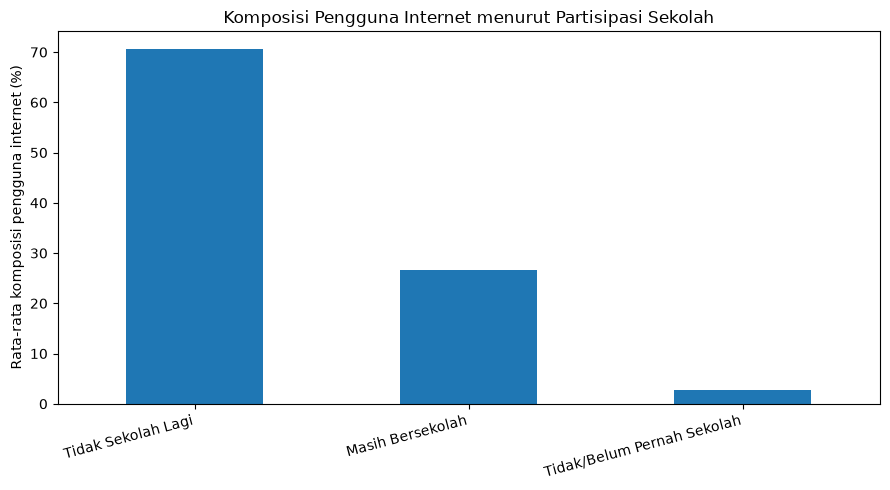

In [12]:
participation_cols = [
    "Tidak/Belum Pernah Sekolah",
    "Masih Bersekolah",
    "Tidak Sekolah Lagi"
]

participation_mean = df[participation_cols].mean().sort_values(ascending=False)
display(participation_mean.to_frame("Rata-rata persentase antarprovinsi").round(2))

participation_mean.plot(kind="bar", figsize=(9, 5))
plt.ylabel("Rata-rata komposisi pengguna internet (%)")
plt.title("Komposisi Pengguna Internet menurut Partisipasi Sekolah")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 8. Analisis hubungan deskriptif antarindikator

Bagian ini mengeksplorasi apakah provinsi dengan persentase desa tanpa sinyal lebih tinggi cenderung memiliki komposisi pengguna internet yang berbeda, serta hubungan deskriptif antara kepemilikan komputer dan komposisi pengguna internet.

**Peringatan:** Tabel 13 dan 14 tidak mengukur tingkat penetrasi internet dalam kelompok pendidikan/status sekolah. Karena itu, hasil scatter dan korelasi tidak boleh disebut sebagai dampak sinyal terhadap partisipasi sekolah atau tingkat akses internet pelajar. Hasil hanya menggambarkan asosiasi antarindikator yang definisinya berbeda.

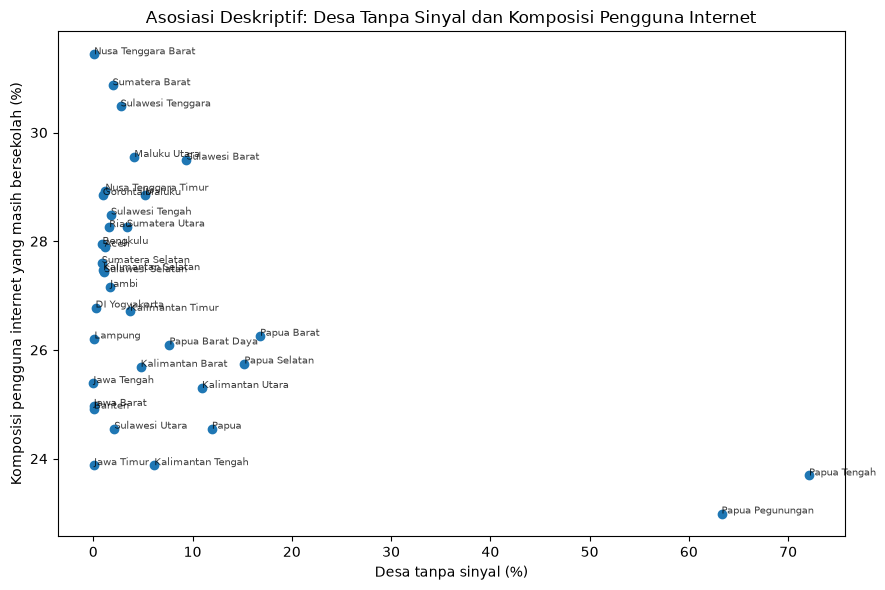

Korelasi Pearson deskriptif: -0.457


In [13]:
# Scatter: desa tanpa sinyal vs komposisi pengguna internet yang masih bersekolah
school_access = df.dropna(subset=["Total_Desa", "Desa_Tanpa_Sinyal"]).copy()
school_access["Persentase_Desa_Tanpa_Sinyal"] = (
    school_access["Desa_Tanpa_Sinyal"] /
    school_access["Total_Desa"] * 100
)

plt.figure(figsize=(9, 6))
plt.scatter(
    school_access["Persentase_Desa_Tanpa_Sinyal"],
    school_access["Masih Bersekolah"]
)
for _, row in school_access.iterrows():
    plt.annotate(
        row["Provinsi"],
        (row["Persentase_Desa_Tanpa_Sinyal"], row["Masih Bersekolah"]),
        fontsize=7, alpha=0.75
    )
plt.xlabel("Desa tanpa sinyal (%)")
plt.ylabel("Komposisi pengguna internet yang masih bersekolah (%)")
plt.title("Asosiasi Deskriptif: Desa Tanpa Sinyal dan Komposisi Pengguna Internet")
plt.tight_layout()
plt.show()

corr = school_access[
    ["Persentase_Desa_Tanpa_Sinyal", "Masih Bersekolah"]
].corr().iloc[0, 1]

print("Korelasi Pearson deskriptif:", round(corr, 3))

## 9. Identifikasi awal bottleneck infrastruktur

Untuk eksplorasi kuadran, gunakan:
- Sumbu X: persentase desa tanpa sinyal.
- Sumbu Y: persentase rumah tangga yang memiliki/menguasai komputer (`Perkotaan+Perdesaan`).

Ambang kuadran menggunakan rata-rata sederhana antarprovinsi pada provinsi yang memiliki kedua indikator. Kuadran ini merupakan alat prioritisasi deskriptif, bukan ukuran resmi kebutuhan intervensi.

Rata-rata desa tanpa sinyal: 7.48 %
Rata-rata rumah tangga komputer gabungan: 17.71 %


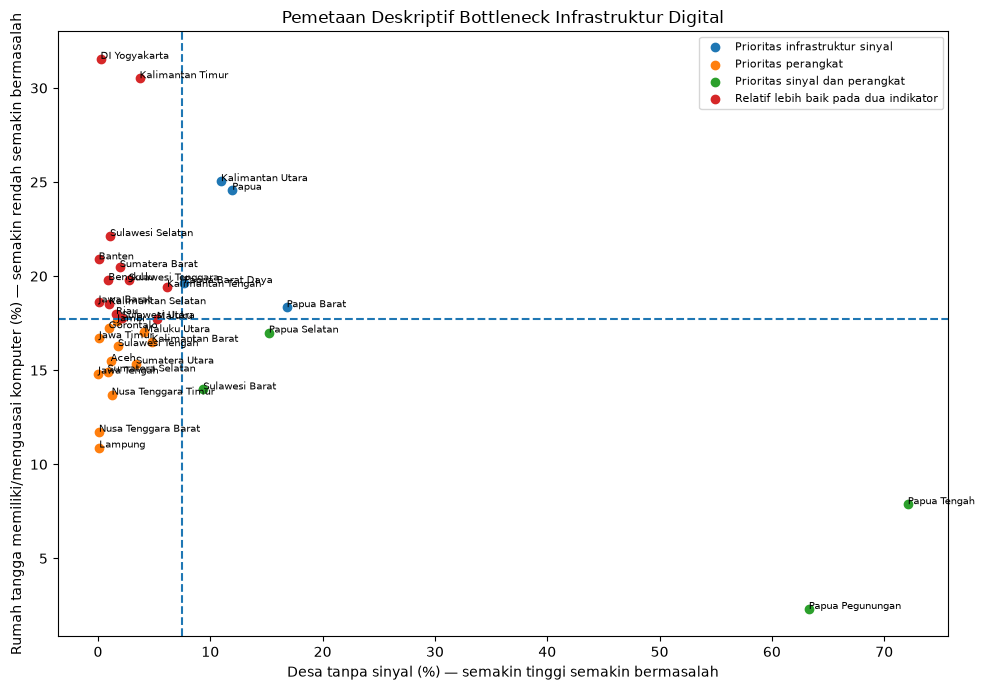

,Provinsi,Wilayah,Persentase_Desa_Tanpa_Sinyal,Perkotaan+Perdesaan,Tipe_Bottleneck
32,Papua Barat,Papua,16.804124,18.35,Prioritas infrastruktur sinyal
34,Papua,Papua,11.953353,24.59,Prioritas infrastruktur sinyal
23,Kalimantan Utara,Kalimantan,10.950413,25.05,Prioritas infrastruktur sinyal
33,Papua Barat Daya,Papua,7.670455,19.63,Prioritas infrastruktur sinyal
19,Kalimantan Barat,Kalimantan,4.775151,16.51,Prioritas perangkat
31,Maluku Utara,Maluku,4.135649,17.02,Prioritas perangkat
1,Sumatera Utara,Sumatera,3.386226,15.35,Prioritas perangkat
25,Sulawesi Tengah,Sulawesi,1.780415,16.28,Prioritas perangkat
4,Jambi,Sumatera,1.703470,17.60,Prioritas perangkat
18,Nusa Tenggara Timur,Bali dan Nusa Tenggara,1.215376,13.70,Prioritas perangkat


In [14]:
bottleneck = df.dropna(
    subset=["Total_Desa", "Desa_Tanpa_Sinyal", "Perkotaan+Perdesaan"]
).copy()

bottleneck["Persentase_Desa_Tanpa_Sinyal"] = (
    bottleneck["Desa_Tanpa_Sinyal"] / bottleneck["Total_Desa"] * 100
)

x_mean = bottleneck["Persentase_Desa_Tanpa_Sinyal"].mean()
y_mean = bottleneck["Perkotaan+Perdesaan"].mean()

def classify_bottleneck(row):
    high_signal_gap = row["Persentase_Desa_Tanpa_Sinyal"] >= x_mean
    low_computer = row["Perkotaan+Perdesaan"] < y_mean

    if high_signal_gap and low_computer:
        return "Prioritas sinyal dan perangkat"
    elif high_signal_gap and not low_computer:
        return "Prioritas infrastruktur sinyal"
    elif not high_signal_gap and low_computer:
        return "Prioritas perangkat"
    return "Relatif lebih baik pada dua indikator"

bottleneck["Tipe_Bottleneck"] = bottleneck.apply(classify_bottleneck, axis=1)

print("Rata-rata desa tanpa sinyal:", round(x_mean, 2), "%")
print("Rata-rata rumah tangga komputer gabungan:", round(y_mean, 2), "%")

plt.figure(figsize=(10, 7))
for category, group in bottleneck.groupby("Tipe_Bottleneck"):
    plt.scatter(
        group["Persentase_Desa_Tanpa_Sinyal"],
        group["Perkotaan+Perdesaan"],
        label=category
    )
    for _, row in group.iterrows():
        plt.annotate(
            row["Provinsi"],
            (row["Persentase_Desa_Tanpa_Sinyal"], row["Perkotaan+Perdesaan"]),
            fontsize=7
        )

plt.axvline(x_mean, linestyle="--")
plt.axhline(y_mean, linestyle="--")
plt.xlabel("Desa tanpa sinyal (%) — semakin tinggi semakin bermasalah")
plt.ylabel("Rumah tangga memiliki/menguasai komputer (%) — semakin rendah semakin bermasalah")
plt.title("Pemetaan Deskriptif Bottleneck Infrastruktur Digital")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

display(
    bottleneck[
        ["Provinsi", "Wilayah", "Persentase_Desa_Tanpa_Sinyal",
         "Perkotaan+Perdesaan", "Tipe_Bottleneck"]
    ].sort_values(
        ["Tipe_Bottleneck", "Persentase_Desa_Tanpa_Sinyal"],
        ascending=[True, False]
    )
)

## 10. Ringkasan insight untuk dashboard

Gunakan hasil analisis di atas untuk menulis insight berbasis angka. Jangan menulis kesimpulan kausal. Contoh bentuk narasi yang aman:

- "Provinsi X memiliki persentase desa tanpa sinyal tertinggi di antara provinsi dengan data lengkap."
- "Rata-rata kepemilikan komputer rumah tangga di perkotaan lebih tinggi daripada perdesaan pada provinsi yang dapat dibandingkan."
- "Komposisi pengguna internet pada kategori SMA merupakan kategori dominan di sebagian besar provinsi."
- "Provinsi X masuk kuadran prioritas sinyal dan perangkat berdasarkan ambang rata-rata antarprovinsi."

In [15]:
# Tabel ringkasan kandidat prioritas untuk ditinjau tim
summary = bottleneck.sort_values(
    ["Persentase_Desa_Tanpa_Sinyal", "Perkotaan+Perdesaan"],
    ascending=[False, True]
)

display(summary[
    ["Provinsi", "Wilayah", "Persentase_Desa_Tanpa_Sinyal",
     "Perkotaan+Perdesaan", "Tipe_Bottleneck"]
].head(15).round(2))

,Provinsi,Wilayah,Persentase_Desa_Tanpa_Sinyal,Perkotaan+Perdesaan,Tipe_Bottleneck
36,Papua Tengah,Papua,72.10,7.88,Prioritas sinyal dan perangkat
37,Papua Pegunungan,Papua,63.29,2.31,Prioritas sinyal dan perangkat
32,Papua Barat,Papua,16.80,18.35,Prioritas infrastruktur sinyal
35,Papua Selatan,Papua,15.22,17.00,Prioritas sinyal dan perangkat
34,Papua,Papua,11.95,24.59,Prioritas infrastruktur sinyal
23,Kalimantan Utara,Kalimantan,10.95,25.05,Prioritas infrastruktur sinyal
29,Sulawesi Barat,Sulawesi,9.38,13.98,Prioritas sinyal dan perangkat
33,Papua Barat Daya,Papua,7.67,19.63,Prioritas infrastruktur sinyal
20,Kalimantan Tengah,Kalimantan,6.15,19.43,Relatif lebih baik pada dua indikator
30,Maluku,Maluku,5.23,17.73,Relatif lebih baik pada dua indikator
